In [1]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, SnowballStemmer
from nltk.corpus import stopwords, brown

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

from deep_translator import GoogleTranslator

import nltk

In [2]:
for resource in ["punkt", "stopwords", "brown", "words"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception:
        pass

### **TASK 1: Lowercase Normalization**

In [3]:
corpus = [
    "Apple released a new product in the US.",
    "I ate an apple after lunch.",
    "APPLE shares increased today.",
    "The students visited the Museum.",
    "The museum was closed on Monday.",
    "US citizens voted yesterday.",
    "The teacher asked us to read.",
    "Polish workers arrived in Poland.",
    "I want to polish the table.",
    "NASA launched a satellite.",
    "The satellite sent data to NASA.",
    "Reading helps improve Reading skills."
]

In [4]:
vocab_before = set(word_tokenize(" ".join(corpus)))
lower_corpus = [sentence.lower() for sentence in corpus]
vocab_after = set(word_tokenize(" ".join(lower_corpus)))

print("Task 1")
print("Vocabulary before lowercasing:", len(vocab_before))
print("Vocabulary after lowercasing :", len(vocab_after))

Task 1
Vocabulary before lowercasing: 52
Vocabulary after lowercasing : 46


- **Original**
  - US citizens voted.
  - Apple announced a new phone.
  - I polish the table.
- **Lowercased**
  - us citizens voted.
  - apple announced a new phone.
  - i polish the table.
- **Ambiguity**
  - US = United States; us = pronoun
  - Apple = company; apple = fruit
  - Polish = nationality/language; polish = make shiny

- Lowercasing reduces vocabulary sparsity and usually helps search, text
classification, and language modeling.
- However, it can harm NER because proper names become indistinguishable from ordinary words. It can also harm sentiment and intent systems when capitalization expresses emphasis, such as "HELP" or "GREAT". 
- Search systems may lose useful distinctions such as US/us, Apple/apple, and organization names.

### **TASK 2: Noise Removal**

In [5]:
noisy_texts = [
    "  I LOVE this movie!!! 😊 Visit https://example.com #Movies @reviewer ",
    "<p>Great product!</p> Buy it at www.shop.com 😍",
    "This is bad... really bad 😡 #disappointed",
    "@support Please help me with my order!!!",
    "Amazing service <br> five stars ⭐⭐⭐",
    "Read more at http://news.example.org/article?id=4",
    "The price is $100, not $10!!!",
    "C++ is useful for systems programming.",
    "I can't believe this!!! 😂😂",
    "New blog: https://blog.example.com #NLP",
    "<div>Excellent quality</div> @brand",
    "Worst experience ever... 😞",
    "Follow @company for updates #news",
    "This product is okay     but shipping was slow.",
    "Visit www.example.com now!!! 👍"
]

In [6]:
def remove_urls(text):
    return re.sub(r"(https?://\S+|www\.\S+)", "", text)

def remove_html(text):
    return re.sub(r"<[^>]+>", "", text)

def handle_mentions_hashtags(text, keep_words=True):
    if keep_words:
        text = re.sub(r"[@#](\w+)", r"\1", text)
    else:
        text = re.sub(r"[@#]\w+", "", text)
    return text

def remove_punctuation(text):
    return re.sub(r"[^\w\s]", "", text)

def remove_extra_whitespace(text):
    return re.sub(r"\s+", " ", text).strip()

def clean_text(text, remove_symbols=True):
    text = remove_urls(text)
    text = remove_html(text)
    text = handle_mentions_hashtags(text)
    if remove_symbols:
        text = remove_punctuation(text)
    return remove_extra_whitespace(text)

In [7]:
cleaned = [clean_text(x) for x in noisy_texts]

examples = pd.DataFrame({
    "Before": noisy_texts[:5],
    "After": cleaned[:5]
})

print("\nTask 2: Cleaning examples")
display(examples)


Task 2: Cleaning examples


,Before,After
0,I LOVE this movie!!! 😊 Visit https://example...,I LOVE this movie Visit Movies reviewer
1,<p>Great product!</p> Buy it at www.shop.com 😍,Great product Buy it at
2,This is bad... really bad 😡 #disappointed,This is bad really bad disappointed
3,@support Please help me with my order!!!,support Please help me with my order
4,Amazing service <br> five stars ⭐⭐⭐,Amazing service five stars


In [8]:
text = noisy_texts[0]
order_a = remove_extra_whitespace(remove_punctuation(
    handle_mentions_hashtags(remove_html(remove_urls(text)))))
order_b = remove_punctuation(remove_extra_whitespace(
    handle_mentions_hashtags(remove_html(remove_urls(text)))))
print("Order A:", order_a)
print("Order B:", order_b)

Order A: I LOVE this movie Visit Movies reviewer
Order B: I LOVE this movie  Visit Movies reviewer


Changing the order usually has little effect here, but it can matter when
one operation creates characters that another operation removes.

Over-cleaning examples:
- "C++" may become "C", losing the programming-language identity.
- "$100" may become "100", losing the currency.
- Emojis may contain useful sentiment information.
- Hashtags may provide important topics.


### **TASK 3: Stop Word Removal**

In [9]:
stop_words = set(stopwords.words("english"))
print("\nTask 3")
print("First 20 stop words:", sorted(stop_words)[:20])
print("Total stop words:", len(stop_words))


Task 3
First 20 stop words: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']
Total stop words: 198


In [10]:
documents = [
    "The movie was excellent and the actors performed beautifully.",
    "This film had a slow beginning but a wonderful ending.",
    "The story was predictable, yet the characters were memorable.",
    "A terrible script made the otherwise good movie difficult to enjoy.",
    "The director created an emotional and powerful experience."
] * 12

def tokens(text):
    return re.findall(r"\b[a-zA-Z]+\b", text.lower())

before_tokens = [tokens(d) for d in documents]
after_tokens = [[w for w in row if w not in stop_words] for row in before_tokens]


In [11]:
def statistics(token_lists):
    all_tokens = [x for row in token_lists for x in row]
    return {
        "Token count": len(all_tokens),
        "Vocabulary size": len(set(all_tokens)),
        "Average sentence/document length": np.mean([len(x) for x in token_lists])
    }

stats = pd.DataFrame([
    statistics(before_tokens),
    statistics(after_tokens)
], index=["Before", "After"])
display(stats)

,Token count,Vocabulary size,Average sentence/document length
Before,564,37,9.4
After,336,27,5.6


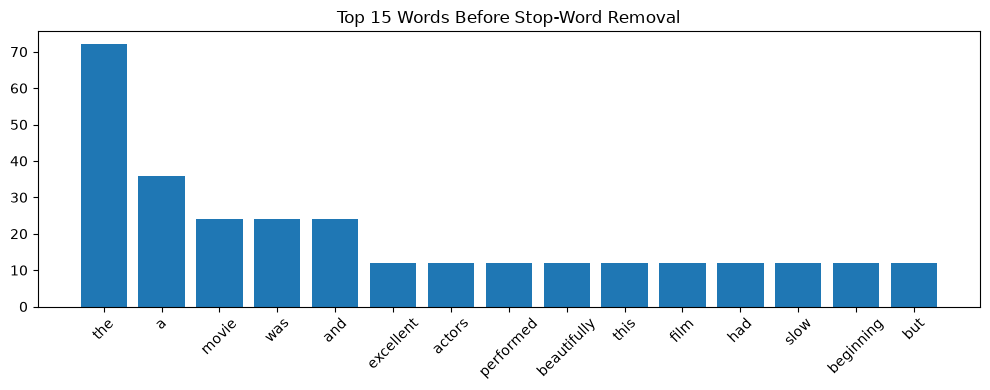

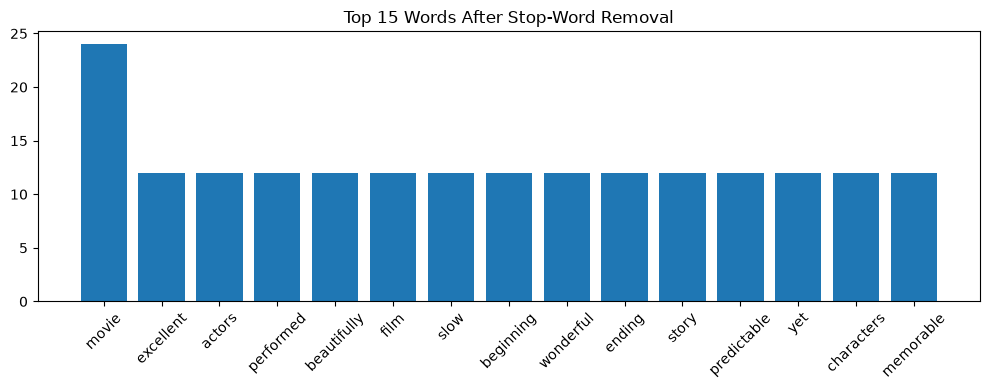

In [12]:

def plot_top15(token_lists, title):
    counts = Counter(x for row in token_lists for x in row)
    top = counts.most_common(15)
    words_, values = zip(*top)
    plt.figure(figsize=(10, 4))
    plt.bar(words_, values)
    plt.title(title)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

plot_top15(before_tokens, "Top 15 Words Before Stop-Word Removal")
plot_top15(after_tokens, "Top 15 Words After Stop-Word Removal")

In [13]:
custom_stop_words = stop_words - {"not", "no", "never", "very"} | {
    "movie", "film", "actor", "director", "story",
    "product", "shipping", "order", "customer", "review"
}
print(custom_stop_words)

{'with', 'which', "we'll", 'up', 'am', 'hadn', "isn't", 'what', "she'll", 'product', 'at', 'this', 'he', "aren't", "couldn't", 'between', 're', "shouldn't", 'some', 'themselves', 'through', "they've", 'isn', 'the', "mightn't", 'couldn', 'my', 'yours', 'an', 'll', 'those', "they'd", 'in', 'd', 'again', 'her', "i've", 'your', 'itself', 'only', "wouldn't", 'film', 'movie', 'as', 'didn', 'she', 'most', 've', 'won', "that'll", 'hers', "i'll", "i'd", 'you', "you'll", 'him', "mustn't", "you'd", 'being', "won't", 'of', 'be', 'actor', 'out', 'on', 'their', 'where', "needn't", 'own', 'ain', "you've", 'why', 'having', 'review', 'after', 'doing', 'mustn', "it'd", "should've", 'have', 'our', 'were', 'do', 'down', 'or', 'for', 'by', 'until', 'aren', 'same', 'other', "she's", 'ourselves', 'when', "we'd", 'ours', 'above', "doesn't", "we're", 'too', "it's", 'shouldn', 'story', 'who', 'needn', "it'll", 'if', 'few', 'yourselves', 'shipping', 'a', 'weren', 'now', 'then', 'such', 'has', 'there', 'order', '

Custom stop-word decisions:
- Added movie, film, actor, director, and story because they are frequent
  domain words and do not distinguish documents in this small movie dataset.
- Added product, shipping, order, customer, and review for a review/support
  domain where these words are generic.
- Removed not, no, never, and very because they affect sentiment and intent.

### **TASK 4: Risks of Stop Word Removal**

In [14]:
sentiment_sentences = [
    "This movie is not good.",
    "I am never happy with this service.",
    "There is no problem with the product.",
    "The experience was not terrible.",
    "I do not recommend this book."
]

risk_table = pd.DataFrame({
    "Original": sentiment_sentences,
    "Blind removal": [
        " ".join(w for w in tokens(s) if w not in stop_words)
        for s in sentiment_sentences
    ],
    "Safe removal": [
        " ".join(w for w in tokens(s) if w not in custom_stop_words)
        for s in sentiment_sentences
    ]
})
display(risk_table)

,Original,Blind removal,Safe removal
0,This movie is not good.,movie good,not good
1,I am never happy with this service.,never happy service,never happy service
2,There is no problem with the product.,problem product,no problem
3,The experience was not terrible.,experience terrible,experience not terrible
4,I do not recommend this book.,recommend book,not recommend book


In [15]:
chatbot_queries = [
    "How do I not get charged?",
    "What is the status of my order?",
    "Can I cancel my subscription?",
    "Why was my payment not accepted?",
    "Where can I find my previous invoice?"
]
display(pd.DataFrame({
    "Original": chatbot_queries,
    "After removal": [
        " ".join(w for w in tokens(q) if w not in stop_words)
        for q in chatbot_queries
    ]
}))

,Original,After removal
0,How do I not get charged?,get charged
1,What is the status of my order?,status order
2,Can I cancel my subscription?,cancel subscription
3,Why was my payment not accepted?,payment accepted
4,Where can I find my previous invoice?,find previous invoice


Safe strategy
  - Retain negations, modal verbs, question words, domain terms
  - Remove only high-frequency words that are irrelevant to intent

In [16]:

# Optional Urdu translation using deep-translator
try:
    translator = GoogleTranslator(source="en", target="ur")
    mt_sentences = [
        "I do not like this product.",
        "Please send my order tomorrow.",
        "The payment was not accepted."
    ]
    mt_rows = []
    for s in mt_sentences:
        reduced = " ".join(w for w in tokens(s) if w not in stop_words)
        mt_rows.append({
            "English": s,
            "Reduced": reduced,
            "Urdu original": translator.translate(s),
            "Urdu reduced": translator.translate(reduced)
        })
    display(pd.DataFrame(mt_rows))
except Exception:
    print("Install deep-translator to run the Urdu translation comparison.")



Install deep-translator to run the Urdu translation comparison.


### **TASK 5: Hands-on with Porter Stemmer**

In [17]:
porter = PorterStemmer()
snowball = SnowballStemmer("english")

words_to_stem = [
    "running", "runs", "ran", "studies", "studying", "happily",
    "generalization", "better", "was", "relational", "relationally",
    "cats", "ponies", "caresses", "agreed", "disabled", "matting",
    "mating", "meeting", "sensational", "traditional", "universities",
    "university", "universe", "organization", "organizational",
    "fairly", "easily", "connection", "connected", "connectionist",
    "friendship", "friendships"
]

stem_table = pd.DataFrame({
    "Word": words_to_stem,
    "Porter stem": [porter.stem(w) for w in words_to_stem],
    "Snowball stem": [snowball.stem(w) for w in words_to_stem]
})
stem_table["Different?"] = stem_table["Porter stem"] != stem_table["Snowball stem"]
display(stem_table)

,Word,Porter stem,Snowball stem,Different?
0,running,run,run,False
1,runs,run,run,False
2,ran,ran,ran,False
3,studies,studi,studi,False
4,studying,studi,studi,False
5,happily,happili,happili,False
6,generalization,gener,general,True
7,better,better,better,False
8,was,wa,was,True
9,relational,relat,relat,False



Over-stemming examples:
1. university and universe may receive similar stems.
2. organization and organize can be conflated.
3. relational and relation can be reduced aggressively.

Under-stemming examples:
1. better and good are related but have different stems.
2. ran and run may not always receive the same stem.
3. studies and study can behave differently depending on the suffix.


### **TASK 6: Lemmatization vs Stemming**

In [18]:
paragraph = """
The students were studying language processing because they wanted to build
better systems. Several researchers had analyzed texts and were comparing
different methods. A good model understands that words change according to
their grammatical roles. The children were running quickly, while the teacher
was explaining difficult concepts. These experiments showed that lemmatization
can return meaningful dictionary forms, whereas stemming often produces
truncated strings. Researchers measured accuracy, speed, and robustness.
They also tested models on social media messages, customer reviews, and news
articles. The results were useful because natural language contains ambiguity,
variation, spelling errors, and many forms of the same word. A carefully
designed preprocessing pipeline should preserve meaning while reducing
unnecessary variation in the input data.
"""

In [19]:
try:
    try:
        nlp = spacy.load("en_core_web_sm")
    except Exception:
        print("Run: python -m spacy download en_core_web_sm")
        nlp = None
except ImportError:
    nlp = None

if nlp:
    doc = nlp(paragraph)
    comparison = pd.DataFrame([
        {
            "Token": t.text,
            "POS": t.pos_,
            "Stem": porter.stem(t.text.lower()) if t.is_alpha else t.text,
            "Lemma": t.lemma_
        }
        for t in doc if not t.is_space
    ])
    display(comparison.head(40))

    start = time.perf_counter()
    porter_results = [porter.stem(t.text.lower()) for t in doc if t.is_alpha]
    porter_time = time.perf_counter() - start

    start = time.perf_counter()
    lemma_results = [t.lemma_ for t in doc if t.is_alpha]
    lemma_time = time.perf_counter() - start

    print("Porter time:", porter_time)
    print("spaCy lemmatization time:", lemma_time)



Run: python -m spacy download en_core_web_sm


### **TASK 7: Preprocessing Pipelines**

In [20]:
base_documents = [
    "This excellent movie has wonderful acting and a powerful story.",
    "The terrible film was boring and badly written.",
    "Amazing customer service solved my order problem quickly.",
    "The product arrived late and the package was damaged.",
    "I loved the beautiful design and easy installation.",
    "The application crashed frequently and lost my data.",
    "The restaurant served delicious food and friendly service.",
    "The meal was cold, expensive, and disappointing."
] * 7  # 56 documents

In [21]:
def preprocess_document(text, lowercase=True, remove_stop=False,
                        stemming=False, lemmatizing=False):
    if lowercase:
        text = text.lower()
    text = clean_text(text)
    word_list = tokens(text)

    if remove_stop:
        word_list = [w for w in word_list if w not in custom_stop_words]

    if stemming:
        word_list = [porter.stem(w) for w in word_list]

    if lemmatizing and nlp:
        word_list = [t.lemma_ for t in nlp(" ".join(word_list))]

    return word_list

configs = {
    "lowercase only": {},
    "lowercase + stopwords": {"remove_stop": True},
    "lowercase + stemming": {"stemming": True},
    "lowercase + lemmatization": {"lemmatizing": True}
}

In [22]:
config_rows = {}
processed = {}

for name, options in configs.items():
    rows = [preprocess_document(d, **options) for d in base_documents]
    processed[name] = rows
    flat = [w for row in rows for w in row]
    config_rows[name] = {
        "Vocabulary size": len(set(flat)),
        "Average tokens/document": np.mean([len(row) for row in rows])
    }

config_table = pd.DataFrame(config_rows).T
display(config_table)

,Vocabulary size,Average tokens/document
lowercase only,50.0,8.250
lowercase + stopwords,36.0,4.625
lowercase + stemming,50.0,8.250
lowercase + lemmatization,50.0,8.250


In [23]:
labels = [1, 0, 1, 0, 1, 0, 1, 0] * 7
results = []

for name, rows in processed.items():
    text_data = [" ".join(row) for row in rows]
    X_train, X_test, y_train, y_test = train_test_split(
        text_data, labels, test_size=.25, random_state=42, stratify=labels
    )
    vectorizer = TfidfVectorizer()
    X_train = vectorizer.fit_transform(X_train)
    X_test = vectorizer.transform(X_test)
    model = MultinomialNB()
    model.fit(X_train, y_train)
    accuracy = accuracy_score(y_test, model.predict(X_test))
    results.append({"Configuration": name, "Accuracy": accuracy})

display(pd.DataFrame(results))

,Configuration,Accuracy
0,lowercase only,1.0
1,lowercase + stopwords,1.0
2,lowercase + stemming,1.0
3,lowercase + lemmatization,1.0


- Lowercasing reduces sparsity.
- Stop-word removal reduces document length but may remove useful grammatical or sentiment information.
- Stemming merges word variants aggressively, while lemmatization creates more readable forms.
- Accuracy depends on the dataset; the best configuration should be selected empirically rather than assumed in advance.

### **TASK 8: Implementing Min Edit Distance**

In [24]:
def levenshtein_recursive(a, b):
    if not a:
        return len(b)
    if not b:
        return len(a)
    cost = 0 if a[-1] == b[-1] else 1
    return min(
        levenshtein_recursive(a[:-1], b) + 1,
        levenshtein_recursive(a, b[:-1]) + 1,
        levenshtein_recursive(a[:-1], b[:-1]) + cost
    )

def levenshtein_dp(a, b, substitution_cost=1, print_table=False):
    dp = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]

    for i in range(len(a) + 1):
        dp[i][0] = i
    for j in range(len(b) + 1):
        dp[0][j] = j

    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            substitution = 0 if a[i - 1] == b[j - 1] else substitution_cost
            dp[i][j] = min(
                dp[i - 1][j] + 1,
                dp[i][j - 1] + 1,
                dp[i - 1][j - 1] + substitution
            )

    if print_table:
        display(pd.DataFrame(dp, index=[""] + list(a), columns=[""] + list(b)))
    return dp[-1][-1], dp

def backtrace(a, b, substitution_cost=1):
    distance, dp = levenshtein_dp(a, b, substitution_cost)
    i, j = len(a), len(b)
    operations = []

    while i > 0 or j > 0:
        if i and j:
            cost = 0 if a[i - 1] == b[j - 1] else substitution_cost
            if dp[i][j] == dp[i - 1][j - 1] + cost:
                if cost:
                    operations.append(("substitute", a[i - 1], b[j - 1]))
                else:
                    operations.append(("match", a[i - 1], b[j - 1]))
                i -= 1
                j -= 1
                continue
        if i and dp[i][j] == dp[i - 1][j] + 1:
            operations.append(("delete", a[i - 1], ""))
            i -= 1
        else:
            operations.append(("insert", "", b[j - 1]))
            j -= 1

    return distance, list(reversed(operations))

pairs = [
    ("intention", "execution"),
    ("kitten", "sitting"),
    ("sunday", "saturday")
]

for a, b in pairs:
    print(f"\n{a} -> {b}")
    distance, table = levenshtein_dp(a, b, print_table=True)
    print("Distance, substitution cost 1:", distance)
    print("Operations:", backtrace(a, b, 1)[1])
    print("Distance, substitution cost 2:", levenshtein_dp(a, b, 2)[0])

print("""
The recursive algorithm recomputes the same subproblems many times and has
exponential time complexity. Dynamic programming stores previous results and
runs in O(len(a) * len(b)) time.
""")



intention -> execution


,,e,x,e,c,u,t,i,o,n
,0,1,2,3,4,5,6,7,8,9
i,1,1,2,3,4,5,6,6,7,8
n,2,2,2,3,4,5,6,7,7,7
t,3,3,3,3,4,5,5,6,7,8
e,4,3,4,3,4,5,6,6,7,8
n,5,4,4,4,4,5,6,7,7,7
t,6,5,5,5,5,5,5,6,7,8
i,7,6,6,6,6,6,6,5,6,7
o,8,7,7,7,7,7,7,6,5,6
n,9,8,8,8,8,8,8,7,6,5


Distance, substitution cost 1: 5
Operations: [('substitute', 'i', 'e'), ('substitute', 'n', 'x'), ('substitute', 't', 'e'), ('substitute', 'e', 'c'), ('substitute', 'n', 'u'), ('match', 't', 't'), ('match', 'i', 'i'), ('match', 'o', 'o'), ('match', 'n', 'n')]
Distance, substitution cost 2: 8

kitten -> sitting


,,s,i,t,t,i,n,g
,0,1,2,3,4,5,6,7
k,1,1,2,3,4,5,6,7
i,2,2,1,2,3,4,5,6
t,3,3,2,1,2,3,4,5
t,4,4,3,2,1,2,3,4
e,5,5,4,3,2,2,3,4
n,6,6,5,4,3,3,2,3


Distance, substitution cost 1: 3
Operations: [('substitute', 'k', 's'), ('match', 'i', 'i'), ('match', 't', 't'), ('match', 't', 't'), ('substitute', 'e', 'i'), ('match', 'n', 'n'), ('insert', '', 'g')]
Distance, substitution cost 2: 5

sunday -> saturday


,,s,a,t,u,r,d,a,y
,0,1,2,3,4,5,6,7,8
s,1,0,1,2,3,4,5,6,7
u,2,1,1,2,2,3,4,5,6
n,3,2,2,2,3,3,4,5,6
d,4,3,3,3,3,4,3,4,5
a,5,4,3,4,4,4,4,3,4
y,6,5,4,4,5,5,5,4,3


Distance, substitution cost 1: 3
Operations: [('match', 's', 's'), ('insert', '', 'a'), ('insert', '', 't'), ('match', 'u', 'u'), ('substitute', 'n', 'r'), ('match', 'd', 'd'), ('match', 'a', 'a'), ('match', 'y', 'y')]
Distance, substitution cost 2: 4

The recursive algorithm recomputes the same subproblems many times and has
exponential time complexity. Dynamic programming stores previous results and
runs in O(len(a) * len(b)) time.



### **TASK 9: Spelling Correction**

In [25]:
dictionary = set(w.lower() for w in brown.words() if w.isalpha())
print("Dictionary size:", len(dictionary))

Dictionary size: 40234


In [26]:
frequency = Counter(w.lower() for w in brown.words() if w.isalpha())

def suggest(word, k=5, use_frequency=False):
    word = word.lower()
    candidates = []
    for candidate in dictionary:
        distance = levenshtein_dp(word, candidate)[0]
        freq = frequency[candidate]
        candidates.append((distance, -freq if use_frequency else 0, candidate))
    candidates.sort()
    return [candidate for _, _, candidate in candidates[:k]]

misspellings = {
    "recieve": "receive",
    "definately": "definitely",
    "acommodate": "accommodate",
    "seperate": "separate",
    "occured": "occurred",
    " adress": "address",
    "enviroment": "environment",
    " goverment": "government",
    "untill": "until",
    "beleive": "believe",
    "arguement": "argument",
    "wierd": "weird",
    "begining": "beginning",
    " succesful": "successful",
    "responsability": "responsibility"
}

def evaluate(use_frequency=False):
    correct = 0
    rows = []
    for misspelled, expected in misspellings.items():
        misspelled = misspelled.strip()
        predictions = suggest(misspelled, 5, use_frequency)
        top1 = predictions[0]
        correct += top1 == expected
        rows.append({
            "Misspelled": misspelled,
            "Expected": expected,
            "Suggestions": predictions,
            "Top-1": top1
        })
    return correct / len(misspellings), pd.DataFrame(rows)

In [27]:

accuracy_plain, table_plain = evaluate(False)
accuracy_frequency, table_frequency = evaluate(True)

print("\nWithout frequency tie-breaking accuracy:", accuracy_plain)
display(table_plain)
print("With frequency tie-breaking accuracy:", accuracy_frequency)
display(table_frequency)



Without frequency tie-breaking accuracy: 0.8


,Misspelled,Expected,Suggestions,Top-1
0,recieve,receive,"[relieve, believe, receave, recede, receive]",relieve
1,definately,definitely,"[definitely, delicately, defiantly, definable,...",definitely
2,acommodate,accommodate,"[accommodate, accommodated, accommodates, comm...",accommodate
3,seperate,separate,"[separate, desperate, generate, operate, separ...",separate
4,occured,occurred,"[occurred, accused, cured, obscured, occluded]",occurred
5,adress,address,"[address, dress, access, acres, across]",address
6,enviroment,environment,"[environment, environments, enlistment, enrich...",environment
7,goverment,government,"[government, governments, movement, coherent, ...",government
8,untill,until,"[until, intial, still, till, untidy]",until
9,beleive,believe,"[beehive, believe, deceive, receive, relive]",beehive


With frequency tie-breaking accuracy: 0.8666666666666667


,Misspelled,Expected,Suggestions,Top-1
0,recieve,receive,"[relieve, believe, receive, relieved, recipe]",relieve
1,definately,definitely,"[definitely, delicately, definite, indefinitel...",definitely
2,acommodate,accommodate,"[accommodate, accommodates, accommodated, comm...",accommodate
3,seperate,separate,"[separate, operate, separated, desperate, gene...",separate
4,occured,occurred,"[occurred, occur, occupied, occurs, accused]",occurred
5,adress,address,"[address, dress, across, areas, press]",address
6,enviroment,environment,"[environment, environments, environmental, env...",environment
7,goverment,government,"[government, movement, governments, movements,...",government
8,untill,until,"[until, still, till, untie, untold]",until
9,beleive,believe,"[believe, receive, relive, beehive, deceive]",believe
